# **Deep Learning Avanzado (INF3813) - MIA**. <br> Práctico Entrenamiento Autosupervizado: CLIP
---
---

**Profesor:**
- Felipe del Río

**Ayudante:**
- Andreina Cota
---
---

# **Agenda**

>[Deep Learning Avanzado (INF3813) - MIA.  Práctico Entrenamiento Autosupervizado: CLIP](#scrollTo=tHopPtVaNF1K)

>[Agenda](#scrollTo=kEloa5uXLIPK)

>[Inspeccionando a CLIP](#scrollTo=ZS3cYFT2TWB9)

>>[Preámbulo](#scrollTo=0dBeU4b818s4)

>>[Cargamos el Modelo](#scrollTo=1D5aBia_ucDJ)

>[Classificación zero-shot utilizando CLIP](#scrollTo=IPrwC1iF8K0j)

>>[Dataset Food101](#scrollTo=SI2I5ws81vvq)

>>>[Queries para Predicción](#scrollTo=81efcz_FvBzS)

>>>[Visualización de Predicciones](#scrollTo=wHmZFDW1D2bi)

>>>[Rendimiento del Modelo](#scrollTo=Epi3aIt-AG7O)

>>>[Prueba tu propio template](#scrollTo=MTlDDclFyyi2)

>>[Dataset Stanford Cars](#scrollTo=qwbkd4RaAqYt)

>>>[Visualización de Predicciones](#scrollTo=ExqvXy95wt0_)

>>>[Rendimiento en Test](#scrollTo=dh4gAJKCPIVC)

>>>[Prueba con tus propias imágenes](#scrollTo=CO9kxJAf6SDO)

>>[Visualización de Embeddings](#scrollTo=73ce8047)



# Inspeccionando a CLIP

Luego de haber visualizado el funcionamento interno de un transformer, utilizaremos CLIP para ver como se puede aprovechar al máximo esta arquitectura en problemas multi-modales, en este caso, que mezclan texto con imágenes.

Como vimos en clases CLIP es un modelo que nos permite codificar tanto imágenes como texto en vectores de representación comparables entre ellos. Este nos permite ver cual es el texto que más se relaciona con una imágen determinada, y podemos aprovechar este mecanismo para clasificar imágenes con una mayor flexibilidad que en un modelo de clasificación tradicional. En esta tercera parte del laboratorio exploraremos como utilizar CLIP con este fin.

<small>Este notebook fue basado en [el provisto por OpenAI](https://colab.research.google.com/github/openai/clip/blob/master/notebooks/Interacting_with_CLIP.ipynb#scrollTo=uLFS29hnhlY4) con el fin de interacturar con CLIP</small>


## Preámbulo

Primero debemos descargar, instalar e importar las distintas librerías que utilizaremos para este laboratorio.

In [ ]:
!pip install ftfy regex tqdm
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-lrsiwp4r
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-lrsiwp4r
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369548 sha256=27997f6f673f3f999caf840969836c79b5c60a68560d5fe50e7fd1ff229efbf6
  Stored in directory: /tmp/pip-ephem-wheel-cache-4089ngq2/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip


In [ ]:
import os
import skimage
import random
import IPython.display
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

from collections import OrderedDict
import torch
from pkg_resources import packaging

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/tmp/ipykernel_1088/888438603.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


In [ ]:
def bold(text):
    return '\033[1m' + text + '\033[0m'

## Cargamos el Modelo

Luego cargaremos el modelo a utilizar. Utilizando la función `clip.available_models()` podemos listar los diferentes modelos displonibles. Pueden ver más detalles de lo que significa cada modelo en el [paper](https://arxiv.org/pdf/2103.00020.pdf) de CLIP.

Pero, a grandes razgos, **RN** corresponde a un backbone de ResNet para el encoder visual, RN50 correspondría a una ResNet50, y cuando tiene el sufijo `xN`, `x4` por ejemplo, significa que el modelo está escalado para utilizar `N` veces más computo.

Mientras que **ViT** corresponde a un backbone de Vision Transformer. El símbolo `-B` o `-L` corresponde al tamaño del modelo, Base y Large respectivamente y el sufijo `/32` corresponde a que los patches son de `32x32`.

Para este laboratorio usaremos la versión `ViT-B/32`, que está basado en su totalidad en Transformers.



In [ ]:
import clip

clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

Primero carguemos un modelo, no tan grande, para utilizar en esta actividad.

El código a continuación descargará los pesos del modelo preentrenado de forma automática. Una vez cargados, podemos veamos algunas características relevantes del modelo.

In [ ]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [ ]:
model, preprocess = clip.load("ViT-B/32")
model.to(device).eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size

print("Número de parámetros:", f"{np.sum([int(np.prod(p.shape)) for p in model.parameters()]):,}")
print("Resolución de Entrada:", input_resolution)
print("Tamaño del contexto:", context_length)
print(f"Tamaño del vocabulario: {vocab_size:,}")

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 198MiB/s]


Número de parámetros: 151,277,313
Resolución de Entrada: 224
Tamaño del contexto: 77
Tamaño del vocabulario: 49,408


Podemos acceder al preprocesamiento que CLIP realiza sobre las imágenes, en la variable `preprocess`. Este se basa en las transformaciones de PyTorch para transformar una imágen a un tensor normalizado que el modelo puede recibir (recuerden la clase anterior de data augmentation).

In [ ]:
preprocess

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7abce915e200>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

# Classificación zero-shot utilizando CLIP

Ya teniendo el modelo cargado, veamos como se comporta CLIP para clasificar dos set de datos con características distintas entre ellos.



## Dataset Food101

Primero probaremos en el dataset Food101. Este dataset consiste en 101 comidas diferentes y un total de 101.000 imágenes de estas.

In [ ]:
from torchvision.datasets import Food101

food_dataset = Food101(os.path.expanduser("~/.cache"), download=True)

100%|██████████| 5.00G/5.00G [00:59<00:00, 83.9MB/s]


### *Queries* para Predicción

Primero que todo, debemos construir las *queries* que utilizaremos para realizar la clasificación. Recordemos que el modelo que vamos a utilizar está entrenado para entregar una correspondencia entre un texto y una imágen. Por esto, para efectuar clasificaciones tendremos que entregarle la clase que queremos clasificar en forma de texto y para esto usaremos unas *queries* predefinidas.

A continuación, definiremos un *template* para construir nuestras *queries* y veremos algunos ejemplos de las que utilizaremos para clasificar el dataset de Food101.

In [ ]:
query_template = 'A photo of {}, a type of food.'
queries = [query_template.format(label.replace('_', ' ')) for label in food_dataset.classes]
tokenized_queries = clip.tokenize(queries).to(device)

In [ ]:
for query in queries[:10]:
    print(query)

A photo of apple pie, a type of food.
A photo of baby back ribs, a type of food.
A photo of baklava, a type of food.
A photo of beef carpaccio, a type of food.
A photo of beef tartare, a type of food.
A photo of beet salad, a type of food.
A photo of beignets, a type of food.
A photo of bibimbap, a type of food.
A photo of bread pudding, a type of food.
A photo of breakfast burrito, a type of food.


### Visualización de Predicciones

Seleccione una imágen del dataset utilizando el parámetro `index` para ver las predicciones del modelo. Si prefiere elegir una imágen al azar, active el campo de `random_sample`.

In [ ]:
random_sample = True #@param {type:"boolean"}
index = 0 #@param {type:"integer"}


In [ ]:
if random_sample:
    index = random.randint(0, len(food_dataset))
original_image, true_label = food_dataset[index]
image = preprocess(original_image)
image_input = image.unsqueeze(0).to(device)

In [ ]:
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features = model.encode_text(tokenized_queries).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

Podemos explorar algunos de los resultados que genera CLIP, a continuación veremos las dimensiones de los vectores de características producidos, tanto de texto como de la imagen, además de la matriz de similaridades entre los distintos textos e imágenes que le entregamos.

In [ ]:
print('Dim features de la imágen   :', image_features.shape)
print('Dim features del texto      :', text_features.shape)
print('Dim matriz de similaridades :', text_probs.shape)

Dim features de la imágen   : torch.Size([1, 512])
Dim features del texto      : torch.Size([101, 512])
Dim matriz de similaridades : torch.Size([1, 101])


Veamos visualmente como es la predicción de este modelo para el ejemplo seleccionado.

Predicciones Top-5

Clase           Probabilidad
guacamole       0.9993
nachos          0.0003
edamame         0.0001
caesar_salad    0.0001
huevos_ranchero 0.0001

Clase verdadera: guacamole



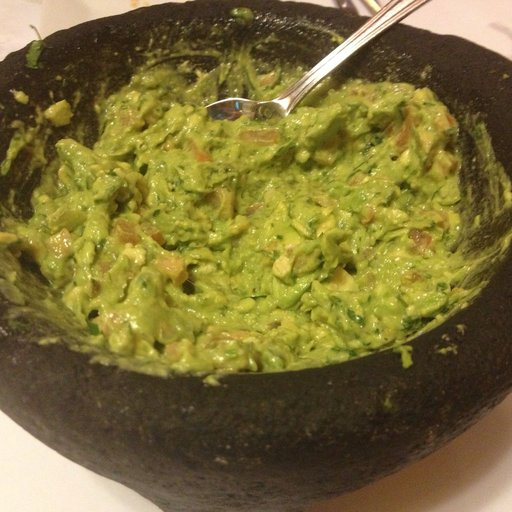

In [ ]:
true_label_name = food_dataset.classes[true_label]

print(bold('Predicciones Top-5\n'))
print(bold(f'Clase          '), bold(f'Probabilidad'))
for prob, label in zip(top_probs[0].tolist(), top_labels[0].tolist()):
    label_name = food_dataset.classes[label]
    if true_label_name == label_name:
        print(bold(f'{label_name:15.15s} {prob:.4f}'))
    else:
        print(f'{label_name:15.15s} {prob:.4f}')

print(bold(f'\nClase verdadera: {true_label_name}'), end='\n\n')
original_image

### Rendimiento del Modelo

Ahora midamos el rendimiento que obtiene este modelo si lo usamos para clasificar en el set de test.

Es importante recordar que el modelo que estamos usando no fue entrenado para clasificar en este, por lo que estamos usando una técnica zero-shot.

In [ ]:
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

def evaluate_model(model, dataset, queries, batch_size=512):
    test_loader = DataLoader(dataset, batch_size=batch_size)

    in_top1 = in_top5 = total = 0.
    total_batches = len(test_dataset) // batch_size
    for image_inputs, true_labels in tqdm(test_loader, total=total_batches):
        image_inputs = image_inputs.to(device)
        with torch.no_grad():
            image_features = model.encode_image(image_inputs).float()
            image_features /= image_features.norm(dim=-1, keepdim=True)
            text_features = model.encode_text(queries).float()
            text_features /= text_features.norm(dim=-1, keepdim=True)

        text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
        top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

        label_match = (top_labels == true_labels.unsqueeze(-1))
        in_top1 += float(label_match[:,0].sum())
        in_top5 += float(label_match.any(-1).sum())
        total += true_labels.numel()

    top1_acc = in_top1 / total
    top5_acc = in_top5 / total

    return top1_acc, top5_acc

In [ ]:
batch_size = 512
test_dataset = Food101(os.path.expanduser("~/.cache"),
                       split='test',
                       transform=preprocess,
                       download=True)

In [ ]:
top1_acc, top5_acc = evaluate_model(
    model, test_dataset, tokenized_queries, batch_size=512)

  0%|          | 0/49 [00:00<?, ?it/s]

In [ ]:
top1_acc = top1_acc * 100
top5_acc = top5_acc * 100
print(f'Top-1 Accuracy: {top1_acc:.2f}%')
print(f'Top-5 Accuracy: {top5_acc:.2f}%')

Top-1 Accuracy: 84.01%
Top-5 Accuracy: 97.31%


### Prueba tu propio template

Ingresa tu *template* en el cuadro de texto de abajo y prueba el rendimiento de CLIP con este.

In [ ]:
Q = "" #@param {type:"string"}

In [ ]:
# ex_queries = [Q.format(label) for label in food_dataset.classes]
# ex_tokenized_queries = clip.tokenize(ex_queries).to(device)

# top1_acc, top5_acc = evaluate_model(
#     model, test_dataset, ex_tokenized_queries, batch_size=512)

# top1_acc = top1_acc * 100
# top5_acc = top5_acc * 100
# print(f'Top-1 Accuracy: {top1_acc:.2f}%')
# print(f'Top-5 Accuracy: {top5_acc:.2f}%')

## Dataset Stanford Cars

Ahora probaremos como le va al modelo en otro dataset, con objetos totalmente distintos a los del anterior. En este caso se trata de un datasets de automoviles. De igual manera que el anterior, el modelo no fue entrenado con estas imágenes en ningún momento.

In [ ]:
!mkdir -p data
if not os.path.exists('data/stanford_cars.zip'):
    !gdown --id 1JkcF--obwMvo2ZocIiKEli3EoE0e6ngt -O data/stanford_cars.zip

!unzip -nq data/\*.zip -d data

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1JkcF--obwMvo2ZocIiKEli3EoE0e6ngt
From (redirected): https://drive.google.com/uc?id=1JkcF--obwMvo2ZocIiKEli3EoE0e6ngt&confirm=t&uuid=9a5f708a-4073-44c2-8662-c7a09d463fb4
To: /content/data/stanford_cars.zip
100% 1.97G/1.97G [00:32<00:00, 60.8MB/s]


In [ ]:
from torchvision.datasets import StanfordCars

cars_dataset = StanfordCars("data/")

De igual manera que para el dataset anterior, debemos definir nuestras *queries*.

In [ ]:
query_template = 'A photo of {}'
queries = [query_template.format(label.replace('_', ' ')) for label in cars_dataset.classes]
tokenized_queries = clip.tokenize(queries).to(device)

In [ ]:
for query in queries[:10]:
    print(query)

A photo of AM General Hummer SUV 2000
A photo of Acura RL Sedan 2012
A photo of Acura TL Sedan 2012
A photo of Acura TL Type-S 2008
A photo of Acura TSX Sedan 2012
A photo of Acura Integra Type R 2001
A photo of Acura ZDX Hatchback 2012
A photo of Aston Martin V8 Vantage Convertible 2012
A photo of Aston Martin V8 Vantage Coupe 2012
A photo of Aston Martin Virage Convertible 2012


### Visualización de Predicciones

Igual que con el dataset anterior, seleccione una imágen del dataset utilizando el parámetro `index` para ver las predicciones del modelo. Si prefiere elegir una imágen al azar, active el campo de `random_sample`.

In [ ]:
random_sample = True #@param {type:"boolean"}
index = 0 #@param {type:"integer"}

In [ ]:
if random_sample:
    index = random.randint(0, len(cars_dataset))
original_image, true_label = cars_dataset[index]
image = preprocess(original_image)
image_input = image.unsqueeze(0).to(device)

In [ ]:
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features = model.encode_text(tokenized_queries).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

Visualicemos el resultado del modelo.

Predicciones Top-5

Clase                Probabilidad
Cadillac SRX SUV 201 0.2203
Cadillac Escalade EX 0.1915
Ford Expedition EL S 0.1200
Jeep Liberty SUV 201 0.0972
Buick Rainier SUV 20 0.0597

Clase verdadera: Cadillac Escalade EXT Crew Cab 2007



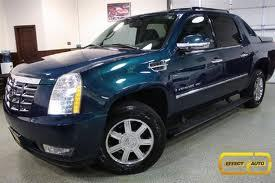

In [ ]:
true_label_name = cars_dataset.classes[true_label]

print(bold('Predicciones Top-5\n'))
print(bold(f'Clase               '), bold(f'Probabilidad'))
for prob, label in zip(top_probs[0].tolist(), top_labels[0].tolist()):
    label_name = cars_dataset.classes[label]
    if true_label_name == label_name:
        print(bold(f'{label_name:20.20s} {prob:.4f}'))
    else:
        print(f'{label_name:20.20s} {prob:.4f}')

print(bold(f'\nClase verdadera: {true_label_name}'), end='\n\n')
original_image

### Rendimiento en Test

Ahora, evaluemos el modelo en el set de test del dataset Stanford Cars.

In [ ]:
from torch.utils.data import DataLoader

batch_size = 512

test_cars_dataset = StanfordCars('data/', split='test',
                                 transform=preprocess)
test_loader = DataLoader(test_cars_dataset, batch_size=batch_size)

In [ ]:
from tqdm.auto import tqdm

in_top1 = in_top5 = total = 0.
total_batches = len(test_cars_dataset) // batch_size
for image_inputs, true_labels in tqdm(test_loader, total=total_batches):
    image_inputs = image_inputs.to(device)
    with torch.no_grad():
        image_features = model.encode_image(image_inputs).float()
        image_features /= image_features.norm(dim=-1, keepdim=True)
        text_features = model.encode_text(tokenized_queries).float()
        text_features /= text_features.norm(dim=-1, keepdim=True)

    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
    top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

    label_match = (top_labels == true_labels.unsqueeze(-1))
    in_top1 += float(label_match[:,0].sum())
    in_top5 += float(label_match.any(-1).sum())
    total += true_labels.numel()

  0%|          | 0/15 [00:00<?, ?it/s]

In [ ]:
top1_acc = in_top1 / total * 100
top5_acc = in_top5 / total * 100
print(f'Top-1 Accuracy: {top1_acc:.2f}%')
print(f'Top-5 Accuracy: {top5_acc:.2f}%')

Top-1 Accuracy: 57.93%
Top-5 Accuracy: 89.64%


### Prueba con tus propias imágenes

Prueba con tus propias imágenes. Utiliza el código a continuación para subir imágenes distintas y queries para estas, las queries deben ser distintas y debe haber una asociada a cada imagen. No necesariamente deben todas seguir el mismo *template*.

In [ ]:
from google.colab import files

uploaded = files.upload()
filenames = list(uploaded.keys())

In [ ]:
from PIL import Image

images = [Image.open(fn) for fn in filenames]
image_inputs = torch.stack([preprocess(image) for image in images]).to(device)

In [ ]:
queries = [
    "A photo of apples, a type of fruit",
    "A photo of pears, a type of fruit",
    "A photo of dog, an animal",
    "A photo of a cat, an animal",
]
# queries = []
tokenized_queries = clip.tokenize(queries).to(device)

In [ ]:
with torch.no_grad():
    image_features = model.encode_image(image_inputs).float()
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features = model.encode_text(tokenized_queries).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1).cpu().numpy().T

In [ ]:
count = len(queries)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)

plt.yticks(range(count), queries, fontsize=14)
plt.xticks([])
for i, image in enumerate(images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features", size=20)
plt.show()

## Visualización de Embeddings

A continuación, visualizaremos los vectores de *embedding* generados por CLIP para las imágenes que subiste y las consultas de texto asociadas. Estos vectores representan las características de cada imagen y texto en un espacio multidimensional, y al visualizarlos podemos entender cómo CLIP relaciona las diferentes modalidades.

In [ ]:
from sklearn.decomposition import PCA
import pandas as pd

# Combine image and text features
all_features = torch.cat([image_features, text_features], dim=0).cpu().numpy()

# Perform PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
reduced_features = pca.fit_transform(all_features)

# Create a DataFrame for easier handling
labels = filenames + queries
feature_type = ['image'] * len(filenames) + ['text'] * len(queries)

df = pd.DataFrame(reduced_features, columns=['x', 'y', 'z'])
df['label'] = labels
df['type'] = feature_type

Hemos combinado las características de las imágenes y el texto y aplicado PCA para reducir su dimensionalidad a 3 componentes. Ahora podemos visualizar estos puntos en un gráfico 3D.

In [ ]:
import plotly.express as px

fig = px.scatter_3d(df, x='x', y='y', z='z', color='type', text='label',
                    title='Visualización 3D de Embeddings (PCA)',
                    labels={'x': 'Componente PCA 1', 'y': 'Componente PCA 2', 'z': 'Componente PCA 3'})

fig.update_traces(textposition='bottom center')
fig.show()

Este gráfico 3D muestra los embeddings de las imágenes y los textos en un espacio de 3 dimensiones. Los puntos están coloreados según su tipo (imagen o texto) y etiquetados con el nombre del archivo de la imagen o la consulta de texto correspondiente.